# K-Nearest Neighbors (KNN) and Naive Bayes

**Learning goals**
- Explain how KNN predicts a class using nearby examples.
- Calculate Euclidean distance by hand and in Python.
- Understand why feature scaling matters for KNN.
- Explain Bayes' theorem, priors, likelihoods, and posterior probabilities.
- Train and evaluate KNN and Gaussian Naive Bayes on simulated data.
- Visualize decision boundaries and compare advantages and limitations.

**How to use this notebook:** Read each Markdown cell first, run the code cell below it, and inspect the output. The datasets are simulated for learning; they are not real student or email records.


## 1. Import the libraries

- `numpy` helps us create and calculate with numerical arrays.
- `pandas` presents data in table form.
- `matplotlib` draws graphs.
- `scikit-learn` provides ready-to-use machine-learning algorithms and evaluation tools.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


# K-Nearest Neighbors (KNN)

## The idea behind KNN

Imagine a new student has studied for a certain number of hours and completed a certain number of practice tests. We already know the results of previous students.

KNN asks:
1. How far is the new student from each known student?
2. Which `K` students are closest?
3. Which result is most common among those neighbors?

KNN is called a **lazy learner** because it does little model-building work in advance; much of the work happens when a prediction is requested.


## Creating a small student dataset

We will use two features so that the examples can be drawn on a 2D graph:
- `StudyHours`: hours spent studying
- `PracticeTests`: number of practice tests completed

The target is `Result`: `Fail` or `Pass`.


In [11]:
student_data = pd.DataFrame({
    "Student": ["A", "B", "C", "D", "E", "F","G","H","I","J"],
    "StudyHours": [1, 1, 2, 2, 3,  4, 5, 6, 6, 7],
    "PracticeTests": [1, 2, 1, 2, 1, 3 , 3, 4,5,6],
    "Result": ["Fail", "Fail", "Fail","Fail","Fail", "Pass", "Pass", "Pass","Pass","Pass"]
})
display(student_data)

,Student,StudyHours,PracticeTests,Result
0,A,1,1,Fail
1,B,1,2,Fail
2,C,2,1,Fail
3,D,2,2,Fail
4,E,3,1,Fail
5,F,4,3,Pass
6,G,5,3,Pass
7,H,6,4,Pass
8,I,6,5,Pass
9,J,7,6,Pass


##  Visualize the known students

Each dot is one known student. The two axes are the two input features. Color represents the known result.

“Which existing points are closest to this location?”


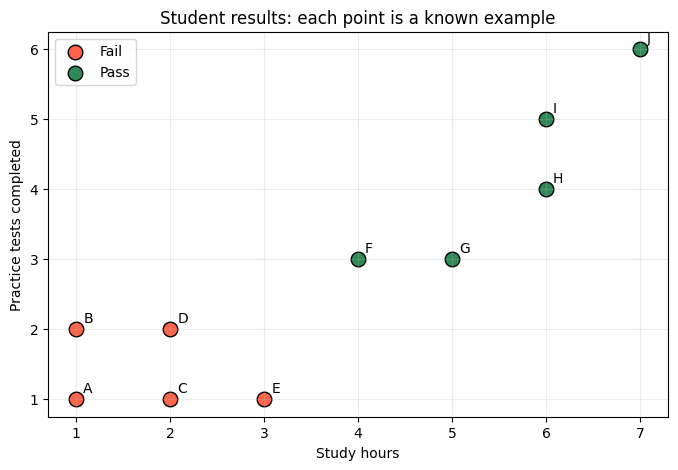

In [12]:
colors = {"Fail": "tomato", "Pass": "seagreen"}
plt.figure(figsize=(8, 5))
for result, group in student_data.groupby("Result"):
    plt.scatter(group["StudyHours"], group["PracticeTests"],
                s=110, label=result, color=colors[result], edgecolor="black")
    for _, row in group.iterrows():
        plt.annotate(row["Student"], (row["StudyHours"], row["PracticeTests"]),
                     xytext=(5, 5), textcoords="offset points")
plt.xlabel("Study hours")
plt.ylabel("Practice tests completed")
plt.title("Student results: each point is a known example")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

# ## Mathematical intuition: Euclidean distance

For two observations with two features, the Euclidean distance is calculated as:

$$
d(A, B) = \sqrt{(x_{A1} - x_{B1})^2 + (x_{A2} - x_{B2})^2}
$$

For a new student $Q = (5, 2)$, let's calculate the distance to student $D = (4, 2)$:

$$
d(Q, D) = \sqrt{(5 - 4)^2 + (2 - 2)^2} = \sqrt{1^2 + 0^2} = \sqrt{1} = 1
$$

Now, let's calculate the distance to student $C = (2, 2)$:

$$
d(Q, C) = \sqrt{(5 - 2)^2 + (2 - 2)^2} = \sqrt{3^2 + 0^2} = \sqrt{9} = 3
$$

Since $d(Q, D) < d(Q, C)$, student $D$ is closer to $Q$ than student $C$ is. The square root formula gives us the straight-line distance between these points.

In [13]:
query = np.array([5, 2])  # 5 study hours, 2 practice tests

features = student_data[["StudyHours", "PracticeTests"]].to_numpy()
distances = np.sqrt(((features - query) ** 2).sum(axis=1))

distance_table = student_data[["Student", "StudyHours", "PracticeTests", "Result"]].copy()
distance_table["DistanceToNewStudent"] = distances
display(distance_table.sort_values("DistanceToNewStudent").reset_index(drop=True))

,Student,StudyHours,PracticeTests,Result,DistanceToNewStudent
0,G,5,3,Pass,1.000000
1,F,4,3,Pass,1.414214
2,H,6,4,Pass,2.236068
3,E,3,1,Fail,2.236068
4,D,2,2,Fail,3.000000
5,C,2,1,Fail,3.162278
6,I,6,5,Pass,3.162278
7,B,1,2,Fail,4.000000
8,A,1,1,Fail,4.123106
9,J,7,6,Pass,4.472136


## 6. Choose K and vote

`K` is the number of nearest neighbors included in the vote. If `K = 3`, select the three rows with the smallest distances and take the majority class.

In this particular dataset, there can be equal distances. A tie in distances is fine; the voting rule still uses the selected neighbors. A tie in class votes may need a tie-breaking rule.


In [14]:
K = 3
nearest_rows = distance_table.sort_values("DistanceToNewStudent").head(K)
display(nearest_rows)

predicted_result = nearest_rows["Result"].mode().iloc[0]
print(f"Prediction for the new student {tuple(query)}: {predicted_result}")

,Student,StudyHours,PracticeTests,Result,DistanceToNewStudent
6,G,5,3,Pass,1.000000
5,F,4,3,Pass,1.414214
7,H,6,4,Pass,2.236068


Prediction for the new student (np.int64(5), np.int64(2)): Pass


## 7. What happens when K changes?

- **Small K:** more sensitive to one unusual or noisy example; may overfit.
- **Large K:** smoother decisions, but distant examples may influence a prediction; may underfit.
- An odd K is often convenient for two-class problems, but it does not guarantee that a tie is impossible in every multiclass case.

The best K is usually chosen using validation or cross-validation, rather than by guessing.


In [16]:
# Try different K values on the small teaching dataset.
from sklearn.neighbors import KNeighborsClassifier

X_small = student_data[["StudyHours", "PracticeTests"]]
y_small = student_data["Result"]

for k in [1, 3, 5,6,8,9]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_small, y_small)
    print(f"K={k}: predicted result for {tuple(query)} -> {model.predict([query])[0]}")

K=1: predicted result for (np.int64(5), np.int64(2)) -> Pass
K=3: predicted result for (np.int64(5), np.int64(2)) -> Pass
K=5: predicted result for (np.int64(5), np.int64(2)) -> Pass
K=6: predicted result for (np.int64(5), np.int64(2)) -> Fail
K=8: predicted result for (np.int64(5), np.int64(2)) -> Fail
K=9: predicted result for (np.int64(5), np.int64(2)) -> Fail


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/pytho

## 8. Feature scaling: why it matters

Imagine one feature is annual income (values in hundreds of thousands) and another is purchase count (values from 1 to 20). The income difference could dominate Euclidean distance simply because its numbers are larger.

Scaling puts features on comparable scales. We use `StandardScaler` in the next example. **Fit the scaler only on training data**; a scikit-learn `Pipeline` makes this easier and helps prevent data leakage.


## 9. Train KNN on simulated data

We create a larger two-feature classification dataset. We split it into training and test sets:
- Training set: examples the model can learn from.
- Test set: held-out examples used to estimate performance on unseen data.

We use a pipeline containing standardization followed by KNN.


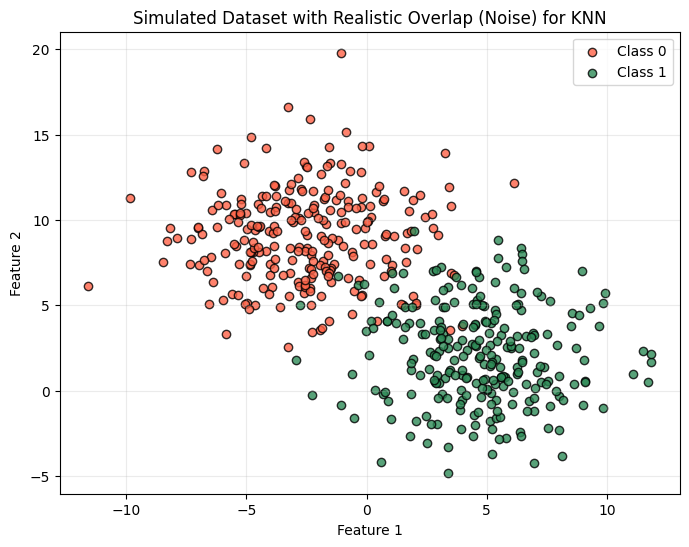

In [21]:
from sklearn.datasets import make_blobs

# Generate a 2D dataset with increased standard deviation to add interesting noise (overlap)
X, y = make_blobs(
    n_samples=500,
    centers=2,
    n_features=2,
    cluster_std=2.8,  # Increased standard deviation to introduce realistic overlap/noise
    random_state=RANDOM_STATE
)

# Visualize the generated classification data with noise
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color="tomato", label="Class 0", edgecolor="black", alpha=0.8)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="seagreen", label="Class 1", edgecolor="black", alpha=0.8)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Simulated Dataset with Realistic Overlap (Noise) for KNN")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [22]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

In [23]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5))


In [24]:
knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

In [25]:
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, knn_predictions, target_names=["Class 0", "Class 1"]))

Test accuracy: 0.976

Classification report:
              precision    recall  f1-score   support

     Class 0       0.98      0.97      0.98        63
     Class 1       0.97      0.98      0.98        62

    accuracy                           0.98       125
   macro avg       0.98      0.98      0.98       125
weighted avg       0.98      0.98      0.98       125



## 10. Visualize the KNN decision boundary

A decision boundary shows how the trained model classifies different locations in the feature space. The background indicates the predicted class for each location; the dots are actual simulated observations.

This helps explain that KNN can create nonlinear decision boundaries rather than fitting only one straight line.


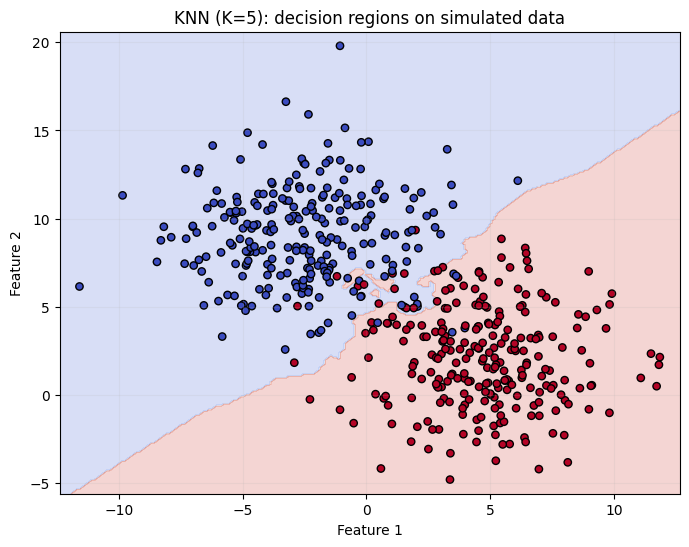

In [26]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.8, X[:, 0].max() + 0.8
    y_min, y_max = X[:, 1].min() - 0.8, X[:, 1].max() + 0.8
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, zz, alpha=0.22, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm",
                edgecolor="black", s=28)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.grid(alpha=0.15)
    plt.show()

plot_decision_boundary(knn_model, X, y, "KNN (K=5): decision regions on simulated data")

## 11. KNN advantages and limitations

**Advantages**
- Easy to explain and implement.
- Can model complex, nonlinear boundaries.
- Can be used for classification and regression.

**Limitations**
- Prediction can be slow when the training set is large.
- Sensitive to feature scaling and irrelevant features.
- Can struggle when there are many features (the curse of dimensionality).
- Requires choosing K and a distance measure.


# 2. Naive Bayes

##  The probability idea

Naive Bayes predicts a class by combining three main components:
- **Prior ($P(C)$)**: How common a class is before seeing the new features.
- **Likelihood ($P(X \mid C)$)**: How likely the observed feature is within a given class.
- **Posterior ($P(C \mid X)$)**: The updated probability of the class after observing the features.

### Bayes' Theorem Formula

$$
P(C \mid X) = \frac{P(X \mid C) P(C)}{P(X)}
$$

For classification, we compare the scores across different classes. Since the evidence term $P(X)$ is constant for all classes, we only need to compare the numerator:

$$
\text{Score}(C) = P(C) P(X \mid C)
$$

When dealing with multiple features, Naive Bayes makes the simplifying **conditional independence assumption**:

$$
\text{Score}(C) = P(C) \prod_{i=1}^{n} P(X_i \mid C)
$$

This means the features do not need to be independent overall; rather, they are assumed to be independent **given the class**.

## 13. Work through a spam example by hand

Suppose we have 100 emails:
- 40 Spam, 60 Not Spam.
- 30 of the Spam emails contain “Free”.
- 6 of the Not Spam emails contain “Free”.

Priors:
- `P(Spam) = 40/100 = 0.40`
- `P(Not Spam) = 60/100 = 0.60`

Likelihoods:
- `P(Free | Spam) = 30/40 = 0.75`
- `P(Free | Not Spam) = 6/60 = 0.10`

Class scores:
- Spam: `0.40 × 0.75 = 0.30`
- Not Spam: `0.60 × 0.10 = 0.06`

Normalize the scores:
- `P(Spam | Free) = 0.30 / (0.30 + 0.06) = 0.8333`
- `P(Not Spam | Free) = 0.06 / (0.30 + 0.06) = 0.1667`

Prediction: **Spam**, because it has the larger posterior probability.

Notice that the prior alone favored Not Spam (60%), but the evidence “Free” changes the prediction.


In [ ]:
# Verify the hand calculation with Python
prior_spam = 40 / 100
prior_not_spam = 60 / 100
likelihood_free_given_spam = 30 / 40
likelihood_free_given_not_spam = 6 / 60

score_spam = prior_spam * likelihood_free_given_spam
score_not_spam = prior_not_spam * likelihood_free_given_not_spam
evidence = score_spam + score_not_spam

posterior_spam = score_spam / evidence
posterior_not_spam = score_not_spam / evidence

print("Spam score:", score_spam)
print("Not Spam score:", score_not_spam)
print("P(Spam | Free):", round(posterior_spam, 4))
print("P(Not Spam | Free):", round(posterior_not_spam, 4))

## 14. Visualize the probability calculation

The bars show the posterior probabilities from the worked example. They are conditional probabilities based on the stated counts, not universal spam-detection rates.


In [ ]:
plt.figure(figsize=(7, 4))
labels = ["Spam", "Not Spam"]
values = [posterior_spam, posterior_not_spam]
plt.bar(labels, values)
plt.ylim(0, 1)
plt.ylabel("Posterior probability")
plt.title('Class probabilities after observing the word "Free"')
for i, value in enumerate(values):
    plt.text(i, value + 0.025, f"{value:.1%}", ha="center")
plt.show()

## 15. Why is it called “naive”?

For an email with several words such as “Free”, “Win”, and “Prize”, Naive Bayes combines the class prior with the likelihood of each word. It makes a simplifying assumption that each feature is conditionally independent of the others given the class.

Real words are often related, so the assumption is not literally true. The simplification makes the calculation practical and can still give useful predictions.


## 16. Train Gaussian Naive Bayes on simulated data

There are different Naive Bayes variants for different feature types:
- **GaussianNB**: continuous numeric features, modeled using a Gaussian (normal) distribution within each class.
- **MultinomialNB**: nonnegative counts, commonly used for word counts in text classification.
- **BernoulliNB**: binary features, such as whether a word appears or not.

We will use `GaussianNB` on the same simulated numeric data for a fair, simple comparison with KNN.


In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, nb_predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, nb_predictions, target_names=["Class 0", "Class 1"]))

## 17. Visualize the Naive Bayes decision regions

The plotting function is the same, but now it asks Gaussian Naive Bayes to predict each location. Compare the shape of its regions with KNN's regions.

Gaussian Naive Bayes estimates class-specific distributions for each feature. Its boundaries can differ from KNN because it relies on a probability model rather than neighbor voting.


In [ ]:
plot_decision_boundary(nb_model, X, y, "Gaussian Naive Bayes: decision regions on simulated data")

## 18. Inspect predicted probabilities

`predict_proba` returns a probability estimate for each class. The column order is given by `model.classes_`. These are model-based estimates and should not automatically be treated as perfectly calibrated real-world probabilities.


In [ ]:
sample_rows = X_test[:5]
probabilities = nb_model.predict_proba(sample_rows)

probability_table = pd.DataFrame(
    probabilities,
    columns=[f"P(Class {cls})" for cls in nb_model.classes_]
)
probability_table["Predicted class"] = nb_model.predict(sample_rows)
display(probability_table)

## 19. Naive Bayes advantages and limitations

**Advantages**
- Fast to train and predict.
- Often effective for text classification and high-dimensional sparse data.
- Works with relatively small training datasets.
- Produces class probability estimates.

**Limitations**
- Conditional independence is often unrealistic.
- Zero-frequency feature values can make a class score zero; smoothing helps for count-based models.
- GaussianNB assumes a Gaussian distribution for each numeric feature within each class.
- Probability estimates may be poorly calibrated, even when classification accuracy is good.

**Teaching takeaway:** Naive Bayes predicts using class probabilities and feature likelihoods.


# Part C — Compare the algorithms

| Question | KNN | Naive Bayes |
|---|---|---|
| Main idea | Find similar nearby examples | Compare class probabilities |
| How prediction works | Distance + voting | Prior × likelihood |
| Training | Stores examples; little fitting | Estimates class and feature distributions |
| Feature scaling | Often important | Usually not required in the same way |
| Common use | Local pattern classification, regression | Text classification, fast probabilistic baselines |
| Main limitation | Prediction cost and distance sensitivity | Independence/distribution assumptions |

## 20. Compare results on the same test split

Accuracy is the fraction of test examples classified correctly. It is useful, but for imbalanced classes also inspect precision, recall, F1-score, and the confusion matrix.


In [ ]:
comparison = pd.DataFrame({
    "Algorithm": ["KNN (K=5, scaled)", "Gaussian Naive Bayes"],
    "Test accuracy": [
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, nb_predictions)
    ]
})
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_predictions, ax=axes[0], colorbar=False
)
axes[0].set_title("KNN confusion matrix")
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_predictions, ax=axes[1], colorbar=False
)
axes[1].set_title("GaussianNB confusion matrix")
plt.tight_layout()
plt.show()

# Part D — Quick practice questions

Try answering before looking at the suggested answers.

1. In KNN, what does K mean?
2. Why can feature scaling change KNN predictions?
3. What happens if K is too small? What might happen if K is too large?
4. In Bayes' theorem, what is a prior?
5. In the spam example, why did the prediction change from the prior preference for Not Spam to Spam?
6. Why is Naive Bayes called “naive”?
7. Which Naive Bayes variant is commonly suitable for word counts?
8. Name one advantage and one limitation of each algorithm.

## Suggested answers

1. The number of nearest training examples used to vote.
2. Features with larger numeric scales can dominate distance calculations.
3. Small K can be sensitive to noise; large K can smooth over local patterns.
4. The probability of a class before considering the new evidence.
5. “Free” was much more likely in Spam emails in the example.
6. It assumes features are conditionally independent given the class.
7. Multinomial Naive Bayes.
8. KNN is intuitive but can be slow at prediction; Naive Bayes is fast but its assumptions may not match real data.


## Final recap

- **KNN:** “Who are the closest examples, and what class do they have?”
- **Naive Bayes:** “Given these features, which class has the greatest posterior probability?”

Both are supervised learning algorithms for classification. KNN can also be used for regression. Choose between them based on the data, assumptions, evaluation metrics, and practical requirements—not on accuracy alone.
